# 03 — Transfer Learning: ResNet50 vs EfficientNet-B0

Model yang sudah dilatih di jutaan gambar (ImageNet) dipakai ulang dan disesuaikan untuk daun cabai.
Hasilnya dibandingkan dengan **baseline CNN** dari notebook 02.

Strategi *fine-tuning* dua tahap:
1. **Tahap 1 (2 epoch):** backbone dibekukan, hanya lapisan klasifikasi baru yang belajar.
2. **Tahap 2 (maks. 10 epoch):** semua lapisan dibuka dengan learning rate kecil, *early stopping* berdasarkan macro F1 validasi.

**Aman bila terputus:** progres disimpan setiap epoch. Jalankan ulang notebook dari atas, training otomatis **melanjutkan** dari epoch terakhir.

**Rekomendasi:** jalankan dengan GPU Colab. ResNet50 di CPU laptop bisa memakan waktu berjam-jam per epoch.
Kalau hanya punya CPU, pakai `MODELS = ["efficientnet_b0"]` (jauh lebih ringan).

## 1. Konfigurasi

In [12]:
import sys, os, json, time, zipfile, copy
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

#MODELS        = ["resnet50", "efficientnet_b0"]   # urutan training
MODELS          = ["efficientnet_b0"]   # urutan training
PRETRAINED    = True       # bobot ImageNet (wajib True untuk transfer learning)
IMG_SIZE      = 224
BATCH_SIZE    = 32
FREEZE_EPOCHS = 2          # tahap 1: hanya kepala klasifikasi
EPOCHS        = 10         # tahap 2: maksimal epoch fine-tuning
LR_HEAD       = 1e-3
LR_FINETUNE   = 1e-4       # learning rate backbone di tahap 2
PATIENCE      = 3
SEED          = 42
QUICK         = False      # True = 20% data, 1 + 1 epoch, untuk cek kode
RESUME        = True       # False = hapus progres lama dan latih ulang dari nol

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT  = Path("/content/drive/MyDrive/dokter-tani")
    DATA_DIR    = Path("/content/data/raw/chilli_leaf")
    if not DATA_DIR.exists():
        print("Mengekstrak dataset dari Drive (sekali per sesi)...")
        with zipfile.ZipFile(DRIVE_ROOT / "chilli_leaf.zip") as z:
            z.extractall(DATA_DIR)
    SPLITS_CSV  = DRIVE_ROOT / "splits.csv"
    REPORTS_DIR = DRIVE_ROOT / "reports" / "models"
    CKPT_DIR    = DRIVE_ROOT / "checkpoints"
else:
    DATA_DIR    = PROJECT_ROOT / "data" / "raw" / "chilli_leaf"
    SPLITS_CSV  = PROJECT_ROOT / "data" / "splits.csv"
    REPORTS_DIR = PROJECT_ROOT / "reports" / "models"
    CKPT_DIR    = PROJECT_ROOT / "checkpoints"

if QUICK:
    FREEZE_EPOCHS, EPOCHS = 1, 1

OUT_DIR = REPORTS_DIR / "transfer_learning"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print("Berjalan di:", "Colab" if IN_COLAB else "laptop", "| QUICK:", QUICK, "| RESUME:", RESUME)
print("Model     :", MODELS)
assert DATA_DIR.exists() and SPLITS_CSV.exists(), "Dataset atau splits.csv belum ada. Jalankan notebook 01 dulu."

Berjalan di: laptop | QUICK: False | RESUME: True
Model     : ['efficientnet_b0']


In [13]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
NUM_WORKERS = 2 if IN_COLAB else 0
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
if DEVICE == "cpu" and "resnet50" in MODELS and not QUICK:
    print("⚠ ResNet50 di CPU akan sangat lama. Pertimbangkan GPU Colab atau MODELS = ['efficientnet_b0'].")

INK, MUTED, GRID = "#18241B", "#5B6660", "#E3E6DC"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # urutan warna tetap per model
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

Device: cpu 


## 2. Data dan augmentasi
Sama persis dengan notebook 02, supaya perbandingannya adil.

In [14]:
splits = pd.read_csv(SPLITS_CSV)
splits["rel_path"] = splits["rel_path"].str.replace("\\", "/", regex=False)
missing = [p for p in splits["rel_path"] if not (DATA_DIR / p).exists()]
if missing:
    raise FileNotFoundError(f"{len(missing)} file tidak ditemukan, contoh: {missing[:3]}")
if QUICK:
    splits = splits.groupby(["split", "label"]).sample(frac=0.2, random_state=SEED)

CLASSES = sorted(splits["label"].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class LeafDataset(Dataset):
    def __init__(self, frame, tfm):
        self.paths = [DATA_DIR / p for p in frame["rel_path"]]
        self.targets = frame["label"].map(CLASS_TO_IDX).to_numpy()
        self.tfm = tfm
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            img = ImageOps.exif_transpose(im).convert("RGB")
        return self.tfm(img), int(self.targets[i])

df_train = splits[splits["split"] == "train"].reset_index(drop=True)
df_val   = splits[splits["split"] == "val"].reset_index(drop=True)
df_test  = splits[splits["split"] == "test"].reset_index(drop=True)

pin = DEVICE == "cuda"
train_dl = DataLoader(LeafDataset(df_train, train_tfms), batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=pin)
val_dl   = DataLoader(LeafDataset(df_val,   eval_tfms),  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_dl  = DataLoader(LeafDataset(df_test,  eval_tfms),  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

counts = df_train["label"].value_counts().reindex(CLASSES).to_numpy()
class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)
print(f"Train {len(df_train):,} | val {len(df_val):,} | test {len(df_test):,} | {NUM_CLASSES} kelas")

Train 5,539 | val 1,216 | test 1,181 | 6 kelas


## 3. Model dan fungsi training

- **ResNet50**: ±25 juta parameter, kuat tetapi berat.
- **EfficientNet-B0**: ±5 juta parameter, ringan; cocok untuk server CPU gratis di Hugging Face Spaces.

Lapisan klasifikasi bawaan (1000 kelas ImageNet) diganti dengan lapisan baru untuk 6 kelas daun cabai.

In [15]:
def build_model(arch):
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if PRETRAINED else None)
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, NUM_CLASSES))
        head = m.fc
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if PRETRAINED else None)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, NUM_CLASSES))
        head = m.classifier
    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")
    head_params = list(head.parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in m.parameters() if id(p) not in head_ids]
    return m.to(DEVICE), head_params, backbone_params

def make_optimizer(stage, head_params, backbone_params):
    if stage == 1:   # backbone beku
        for p in backbone_params: p.requires_grad = False
        opt = torch.optim.AdamW(head_params, lr=LR_HEAD, weight_decay=1e-4)
    else:            # semua lapisan belajar, backbone dengan LR kecil
        for p in backbone_params: p.requires_grad = True
        opt = torch.optim.AdamW([{"params": backbone_params, "lr": LR_FINETUNE},
                                 {"params": head_params, "lr": LR_FINETUNE * 5}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.3, patience=1)
    return opt, sched

use_amp = DEVICE == "cuda"

def run_epoch(model, loader, train, optimizer=None, scaler=None):
    model.train(train)
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False, desc="train" if train else "eval"):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type="cuda", enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
            total_loss += loss.item() * len(y)
            y_true += y.tolist(); y_pred += logits.argmax(1).tolist()
    return total_loss / len(loader.dataset), np.array(y_true), np.array(y_pred)

In [16]:
def train_arch(arch):
    best_path, last_path = CKPT_DIR / f"{arch}_best.pt", CKPT_DIR / f"{arch}_last.pt"
    arch_dir = OUT_DIR / arch; arch_dir.mkdir(parents=True, exist_ok=True)
    if not RESUME:
        for p in (best_path, last_path): p.unlink(missing_ok=True)

    model, head_p, back_p = build_model(arch)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    state = {"epoch": 0, "stage": 1, "best_f1": -1.0, "bad": 0, "history": [], "finished": False}

    if last_path.exists():
        ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); state = ck["state"]
        opt, sched = make_optimizer(state["stage"], head_p, back_p)
        opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        if state["finished"]:
            print(f"[{arch}] Sudah selesai sebelumnya (epoch {state['epoch']}, F1 val terbaik {state['best_f1']:.3f}). Dilewati.")
            return state
        print(f"[{arch}] Melanjutkan dari epoch {state['epoch']} (tahap {state['stage']}).")
    else:
        opt, sched = make_optimizer(1, head_p, back_p)
        print(f"[{arch}] Mulai dari awal | {sum(p.numel() for p in model.parameters())/1e6:.1f} jt parameter")

    total = FREEZE_EPOCHS + EPOCHS
    for epoch in range(state["epoch"] + 1, total + 1):
        if epoch > FREEZE_EPOCHS and state["stage"] == 1:
            state["stage"] = 2
            opt, sched = make_optimizer(2, head_p, back_p)
            print(f"[{arch}] Tahap 2: semua lapisan dibuka (fine-tuning)")
        t0 = time.time()
        tr_loss, tr_y, tr_p = run_epoch(model, train_dl, True, opt, scaler)
        va_loss, va_y, va_p = run_epoch(model, val_dl, False)
        va_f1, va_acc = float(f1_score(va_y, va_p, average="macro")), float(accuracy_score(va_y, va_p))
        if state["stage"] == 2:
            sched.step(va_f1)

        improved = va_f1 > state["best_f1"]
        if improved:
            state["best_f1"], state["bad"] = va_f1, 0
            torch.save({"arch": arch, "model": model.state_dict(), "classes": CLASSES, "img_size": IMG_SIZE,
                        "mean": MEAN, "std": STD, "epoch": epoch, "val_f1": va_f1}, best_path)
        elif state["stage"] == 2:
            state["bad"] += 1

        state["epoch"] = epoch
        state["history"].append({"epoch": epoch, "stage": state["stage"], "train_loss": float(tr_loss),
                                 "val_loss": float(va_loss), "train_acc": float(accuracy_score(tr_y, tr_p)),
                                 "val_acc": va_acc, "val_f1": va_f1, "seconds": time.time() - t0})
        stop = state["stage"] == 2 and state["bad"] >= PATIENCE
        state["finished"] = stop or epoch == total
        # simpan progres SETIAP epoch, supaya bisa dilanjutkan bila terputus
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "state": state}, last_path)
        pd.DataFrame(state["history"]).to_csv(arch_dir / "history.csv", index=False)

        print(f"[{arch}] Epoch {epoch:2d}/{total} (tahap {state['stage']}) | loss {tr_loss:.3f} / {va_loss:.3f} | "
              f"val acc {va_acc:.3f} | val F1 {va_f1:.3f} {'★' if improved else ''} | {time.time() - t0:.0f} dtk")
        if stop:
            print(f"[{arch}] Early stopping: F1 validasi tidak naik selama {PATIENCE} epoch.")
            break
    return state

## 4. Training
Sel ini yang lama. Kalau terputus, cukup jalankan ulang notebook dari atas (*Run All*); model yang sudah selesai dilewati, yang belum selesai dilanjutkan.

In [17]:
t_all = time.time()
train_states = {}
for arch in MODELS:
    train_states[arch] = train_arch(arch)
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
print(f"\nSesi ini: {(time.time() - t_all) / 60:.1f} menit")

[efficientnet_b0] Mulai dari awal | 4.0 jt parameter


[efficientnet_b0] Epoch  1/12 (tahap 1) | loss 0.825 / 0.491 | val acc 0.845 | val F1 0.853 ★ | 587 dtk


[efficientnet_b0] Epoch  2/12 (tahap 1) | loss 0.490 / 0.381 | val acc 0.882 | val F1 0.891 ★ | 302 dtk
[efficientnet_b0] Tahap 2: semua lapisan dibuka (fine-tuning)


[efficientnet_b0] Epoch  3/12 (tahap 2) | loss 0.235 / 0.115 | val acc 0.961 | val F1 0.963 ★ | 704 dtk


[efficientnet_b0] Epoch  4/12 (tahap 2) | loss 0.117 / 0.101 | val acc 0.963 | val F1 0.965 ★ | 658 dtk


...

[efficientnet_b0] Epoch  8/12 (tahap 2) | loss 0.056 / 0.126 | val acc 0.964 | val F1 0.968  | 654 dtk


[efficientnet_b0] Epoch  9/12 (tahap 2) | loss 0.042 / 0.073 | val acc 0.976 | val F1 0.978 ★ | 673 dtk


[efficientnet_b0] Epoch 10/12 (tahap 2) | loss 0.038 / 0.061 | val acc 0.980 | val F1 0.982 ★ | 653 dtk


[efficientnet_b0] Epoch 11/12 (tahap 2) | loss 0.036 / 0.059 | val acc 0.983 | val F1 0.984 ★ | 653 dtk


[efficientnet_b0] Epoch 12/12 (tahap 2) | loss 0.035 / 0.061 | val acc 0.981 | val F1 0.982  | 653 dtk

Sesi ini: 125.3 menit


### Kurva belajar
Garis putus-putus = saat backbone dibuka (mulai tahap 2).

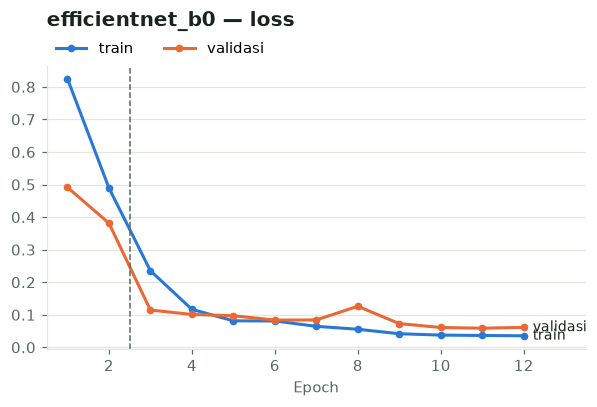

In [18]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5.6 * len(MODELS), 3.8), squeeze=False)
for ax, arch in zip(axes[0], MODELS):
    h = pd.DataFrame(train_states[arch]["history"])
    for col, name, c in [("train_loss", "train", SERIES[0]), ("val_loss", "validasi", SERIES[1])]:
        ax.plot(h["epoch"], h[col], color=c, linewidth=2, marker="o", markersize=4, label=name)
        ax.annotate(name, (h["epoch"].iloc[-1], h[col].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK, fontsize=9)
    ax.axvline(FREEZE_EPOCHS + 0.5, color=MUTED, linestyle="--", linewidth=1)
    ax.set_title(f"{arch} — loss", pad=26); ax.set_xlabel("Epoch")
    ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlim(0.5, h["epoch"].max() + 1.5)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
fig.tight_layout(); fig.savefig(OUT_DIR / "kurva_belajar.png"); plt.show()

## 5. Evaluasi di data test dan perbandingan

Selain akurasi, diukur juga **waktu inferensi per foto di CPU**, karena bot akan berjalan di server CPU gratis.
Model final dipilih berdasarkan **F1 validasi**, bukan test, supaya data test tetap jujur.

In [19]:
def evaluate(arch):
    ck = torch.load(CKPT_DIR / f"{arch}_best.pt", map_location=DEVICE, weights_only=False)
    model, _, _ = build_model(arch)
    model.load_state_dict(ck["model"]); model.eval()
    probs, y_true = [], []
    with torch.no_grad():
        for x, y in tqdm(test_dl, leave=False, desc=f"test {arch}"):
            probs.append(torch.softmax(model(x.to(DEVICE)), 1).float().cpu()); y_true += y.tolist()
    probs = torch.cat(probs).numpy(); y_true = np.array(y_true); y_pred = probs.argmax(1)

    # waktu inferensi 1 foto di CPU (seperti di server Hugging Face Spaces gratis)
    cpu_model = copy.deepcopy(model).cpu().eval()
    x1 = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with torch.no_grad():
        for _ in range(3): cpu_model(x1)
        t0 = time.time()
        for _ in range(20): cpu_model(x1)
    ms = (time.time() - t0) / 20 * 1000

    rep = classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASSES,
                                output_dict=True, zero_division=0)
    recall = {c: round(rep[c]["recall"], 3) for c in CLASSES}
    h = pd.DataFrame(train_states[arch]["history"])
    return {"model": arch, "params_jt": round(sum(p.numel() for p in model.parameters()) / 1e6, 1),
            "val_macro_f1": round(float(ck["val_f1"]), 4),
            "test_accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "test_macro_f1": round(float(f1_score(y_true, y_pred, average="macro")), 4),
            "recall_terendah": round(min(recall.values()), 3),
            "cpu_ms_per_foto": round(ms, 1), "train_menit": round(float(h["seconds"].sum()) / 60, 1),
            "best_epoch": int(ck["epoch"]), "_recall": recall, "_y_true": y_true, "_y_pred": y_pred}

results = {arch: evaluate(arch) for arch in MODELS}

rows = []
base_path = REPORTS_DIR / "baseline_cnn" / "metrics.json"
if base_path.exists():
    b = json.loads(base_path.read_text())
    rows.append({"model": "baseline_cnn", "params_jt": round(b["params"] / 1e6, 1), "val_macro_f1": b["val_macro_f1"],
                 "test_accuracy": b["test_accuracy"], "test_macro_f1": b["test_macro_f1"],
                 "recall_terendah": round(min(b["test_recall_per_class"].values()), 3),
                 "cpu_ms_per_foto": None, "train_menit": b.get("train_minutes"), "best_epoch": b["best_epoch"]})
    base_recall = b["test_recall_per_class"]
else:
    print(f"(metrics baseline tidak ditemukan di {base_path}; perbandingan tanpa baseline)")
    base_recall = None
rows += [{k: v for k, v in r.items() if not k.startswith("_")} for r in results.values()]
compare = pd.DataFrame(rows).set_index("model")
compare.to_csv(OUT_DIR / "perbandingan_model.csv")
compare

,params_jt,val_macro_f1,test_accuracy,test_macro_f1,recall_terendah,cpu_ms_per_foto,train_menit,best_epoch
model,,,,,,,,
baseline_cnn,1.2,0.9616,0.9661,0.9680,0.921,NaN,361.9,24
efficientnet_b0,4.0,0.9841,0.9831,0.9845,0.974,27.1,125.2,11


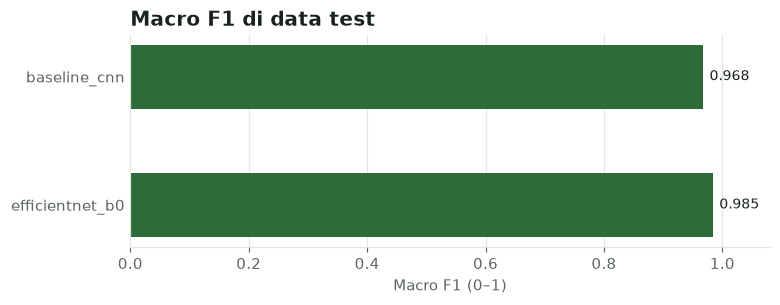

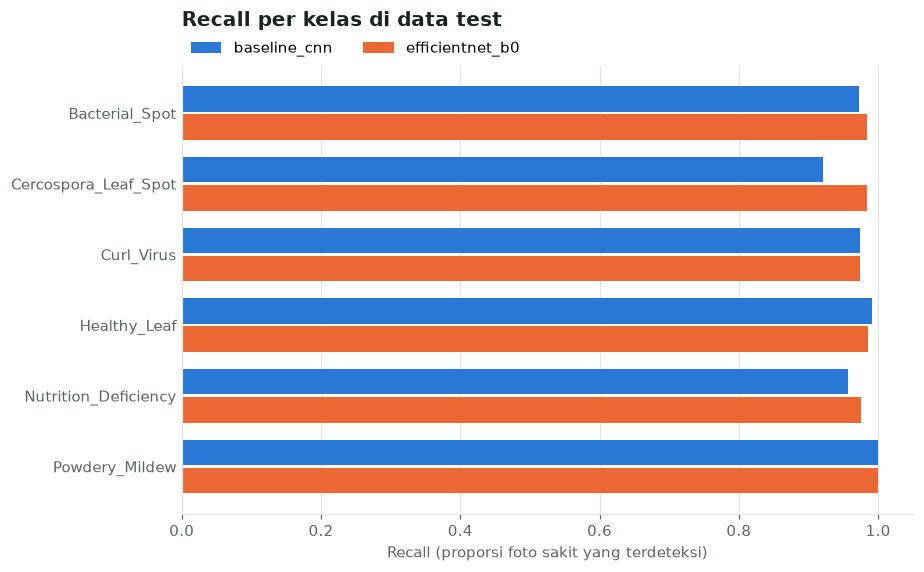

In [20]:
# Grafik 1: macro F1 test per model
order = list(compare.index)
fig, ax = plt.subplots(figsize=(7.5, 0.6 * len(order) + 1.3))
vals = compare["test_macro_f1"].astype(float).values
bars = ax.barh(order, vals, color="#2E6B3A", height=0.5)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in vals], padding=4, color=INK, fontsize=9)
ax.set_xlim(0, 1.08); ax.invert_yaxis()
ax.set_title("Macro F1 di data test"); ax.set_xlabel("Macro F1 (0–1)")
ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(axis="y", length=0)
fig.savefig(OUT_DIR / "perbandingan_f1.png"); plt.show()

# Grafik 2: recall per kelas per model (penyakit yang terlewat = paling merugikan petani)
rec = {a: results[a]["_recall"] for a in MODELS}
if base_recall:
    rec = {"baseline_cnn": base_recall, **rec}
names = list(rec)
y = np.arange(NUM_CLASSES); hgt = 0.8 / len(names)
fig, ax = plt.subplots(figsize=(8.5, 0.55 * NUM_CLASSES * len(names) / 2 + 2))
for k, name in enumerate(names):
    ax.barh(y + k * hgt, [rec[name].get(c, 0) for c in CLASSES], height=hgt * 0.9,
            color=SERIES[k % len(SERIES)], label=name)
ax.set_yticks(y + hgt * (len(names) - 1) / 2, CLASSES); ax.invert_yaxis()
ax.set_xlim(0, 1.05); ax.set_xlabel("Recall (proporsi foto sakit yang terdeteksi)")
ax.set_title("Recall per kelas di data test", pad=26)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=len(names), borderaxespad=0.2)
ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(axis="y", length=0)
fig.tight_layout(); fig.savefig(OUT_DIR / "recall_per_kelas.png"); plt.show()

## 6. Model final
Dipilih berdasarkan F1 validasi tertinggi. File ini yang dipakai untuk Grad-CAM, aplikasi, dan bot.

Model final: efficientnet_b0 | val F1 0.984 | test F1 0.985 | 27 ms/foto di CPU
Disimpan ke: c:\laragon\www\final-project\dokter-tani\checkpoints\dokter_tani_final.pt


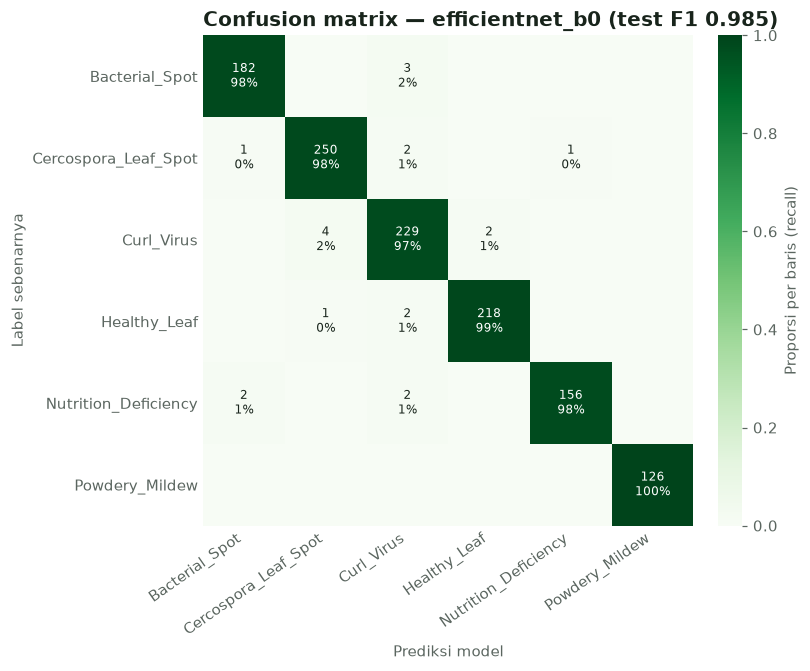

In [21]:
final_arch = max(MODELS, key=lambda a: results[a]["val_macro_f1"])
r = results[final_arch]
ck = torch.load(CKPT_DIR / f"{final_arch}_best.pt", map_location="cpu", weights_only=False)
ck["test_metrics"] = {k: v for k, v in r.items() if not k.startswith("_")}
FINAL_PATH = CKPT_DIR / "dokter_tani_final.pt"
torch.save(ck, FINAL_PATH)
print(f"Model final: {final_arch} | val F1 {r['val_macro_f1']:.3f} | test F1 {r['test_macro_f1']:.3f} | "
      f"{r['cpu_ms_per_foto']:.0f} ms/foto di CPU")
print("Disimpan ke:", FINAL_PATH)

cm = confusion_matrix(r["_y_true"], r["_y_pred"], labels=range(NUM_CLASSES))
cm_pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(cm_pct, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), CLASSES, rotation=35, ha="right"); ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.set_xlabel("Prediksi model"); ax.set_ylabel("Label sebenarnya")
ax.set_title(f"Confusion matrix — {final_arch} (test F1 {r['test_macro_f1']:.3f})")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            ax.text(j, i, f"{cm[i, j]}\n{cm_pct[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if cm_pct[i, j] > 0.55 else INK)
ax.spines[:].set_visible(False); ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("Proporsi per baris (recall)", color=MUTED)
cb.outline.set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / "confusion_matrix_final.png"); plt.show()

## 7. Ringkasan untuk `CATATAN.md`

In [22]:
today = time.strftime("%Y-%m-%d")
lines = []
for arch in MODELS:
    m = results[arch]
    lines.append(f"| {today} | Transfer learning {arch} (beku {FREEZE_EPOCHS} epoch, lalu fine-tune) | "
                 f"test acc {m['test_accuracy']:.3f}, macro F1 {m['test_macro_f1']:.3f}, recall terendah {m['recall_terendah']:.2f}, "
                 f"{m['cpu_ms_per_foto']:.0f} ms/foto CPU | {'Dipilih sebagai model final' if arch == final_arch else 'Pembanding'} |")
summary = {"final_model": final_arch, "compare": compare.reset_index().to_dict(orient="records")}
(OUT_DIR / "metrics.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("\n".join(lines))
print(f"\nHasil tersimpan di: {OUT_DIR}")

| 2026-10-11 | Transfer learning efficientnet_b0 (beku 2 epoch, lalu fine-tune) | test acc 0.983, macro F1 0.985, recall terendah 0.97, 27 ms/foto CPU | Dipilih sebagai model final |

Hasil tersimpan di: c:\laragon\www\final-project\dokter-tani\reports\models\transfer_learning


### Yang perlu diamati
- **Seberapa jauh transfer learning mengalahkan baseline?** Selisih macro F1 ini adalah bukti utama di slide metodologi.
- **ResNet50 vs EfficientNet-B0:** kalau akurasinya mirip, EfficientNet lebih masuk akal untuk deployment karena lebih kecil dan lebih cepat di CPU.
- **Recall per kelas:** kelas mana yang masih lemah? Itu bahan slide *Challenges* dan *Future improvements*.

**Berikutnya:** `04_gradcam.ipynb`, melihat bagian daun mana yang dipakai model untuk memutuskan, lalu upload model final ke Hugging Face Hub.